# What drives the price of a car?

![](images/kurt.jpeg)

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
import pandas as pd

# Load the vehicles dataset from the specified path
csv_path = '/content/Data/vehicles.csv'
df = pd.read_csv(csv_path)

# Display shape, column summary, and the first few rows
print(f"Dataset Shape: {df.shape}\n")
df.info()
print("\n--- First 5 Rows ---")
display(df.head())

Dataset Shape: (426880, 18)

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 426880 entries, 0 to 426879
Data columns (total 18 columns):
 #   Column        Non-Null Count   Dtype  
---  ------        --------------   -----  
 0   id            426880 non-null  int64  
 1   region        426880 non-null  object 
 2   price         426880 non-null  int64  
 3   year          425675 non-null  float64
 4   manufacturer  409234 non-null  object 
 5   model         421603 non-null  object 
 6   condition     252776 non-null  object 
 7   cylinders     249202 non-null  object 
 8   fuel          423867 non-null  object 
 9   odometer      422480 non-null  float64
 10  title_status  418638 non-null  object 
 11  transmission  424324 non-null  object 
 12  VIN           265838 non-null  object 
 13  drive         296313 non-null  object 
 14  size          120519 non-null  object 
 15  type          334022 non-null  object 
 16  paint_color   296677 non-null  object 
 17  state         42688

,id,region,price,year,manufacturer,model,condition,cylinders,fuel,odometer,title_status,transmission,VIN,drive,size,type,paint_color,state
0,7222695916,prescott,6000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,az
1,7218891961,fayetteville,11900,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,ar
2,7221797935,florida keys,21000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,fl
3,7222270760,worcester / central MA,1500,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,ma
4,7210384030,greensboro,4900,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,nc


**OVERVIEW**

In this application, you will explore a dataset from Kaggle. The original dataset contained information on 3 million used cars. The provided dataset contains information on 426K cars to ensure speed of processing.  Your goal is to understand what factors make a car more or less expensive.  As a result of your analysis, you should provide clear recommendations to your client -- a used car dealership -- as to what consumers value in a used car.

### CRISP-DM Framework

<center>
    <img src = images/crisp.png width = 50%/>
</center>


To frame the task, throughout our practical applications, we will refer back to a standard process in industry for data projects called CRISP-DM.  This process provides a framework for working through a data problem.  Your first step in this application will be to read through a brief overview of CRISP-DM [here](https://mo-pcco.s3.us-east-1.amazonaws.com/BH-PCMLAI/module_11/readings_starter.zip).  After reading the overview, answer the questions below.

### Business Understanding

From a business perspective, we are tasked with identifying key drivers for used car prices.  In the CRISP-DM overview, we are asked to convert this business framing to a data problem definition.  Using a few sentences, reframe the task as a data task with the appropriate technical vocabulary.

### Data Understanding

After considering the business understanding, we want to get familiar with our data.  Write down some steps that you would take to get to know the dataset and identify any quality issues within.  Take time to get to know the dataset and explore what information it contains and how this could be used to inform your business understanding.

In [ ]:
import pandas as pd
import numpy as np

# 1. Missing Value Analysis
missing_percent = (df.isnull().sum() / len(df)) * 100
missing_info = pd.DataFrame({
    'Missing Count': df.isnull().sum(),
    'Percentage (%)': missing_percent.round(2)
}).sort_values(by='Percentage (%)', ascending=False)

print("--- Missing Values Summary ---")
display(missing_info)

# 2. Descriptive Statistics for Numeric Columns
print("\n--- Numeric Descriptive Statistics ---")
display(df[['price', 'year', 'odometer']].describe().round(2))

# 3. Basic Check on Outliers and Cardinality of Categorical Columns
print("\n--- Unique Value Counts for Categorical Columns ---")
cat_cols = df.select_dtypes(include=['object']).columns
for col in cat_cols:
    print(f"{col}: {df[col].nunique()} unique values")

--- Missing Values Summary ---


,Missing Count,Percentage (%)
size,306361,71.77
cylinders,177678,41.62
condition,174104,40.79
VIN,161042,37.73
drive,130567,30.59
paint_color,130203,30.50
type,92858,21.75
manufacturer,17646,4.13
title_status,8242,1.93
model,5277,1.24



--- Numeric Descriptive Statistics ---


,price,year,odometer
count,4.268800e+05,425675.00,422480.00
mean,7.519903e+04,2011.24,98043.33
std,1.218228e+07,9.45,213881.50
min,0.000000e+00,1900.00,0.00
25%,5.900000e+03,2008.00,37704.00
50%,1.395000e+04,2013.00,85548.00
75%,2.648575e+04,2017.00,133542.50
max,3.736929e+09,2022.00,10000000.00



--- Unique Value Counts for Categorical Columns ---
region: 404 unique values
manufacturer: 42 unique values
model: 29649 unique values
condition: 6 unique values
cylinders: 8 unique values
fuel: 5 unique values
title_status: 6 unique values
transmission: 3 unique values
VIN: 118246 unique values
drive: 3 unique values
size: 4 unique values
type: 13 unique values
paint_color: 12 unique values
state: 51 unique values


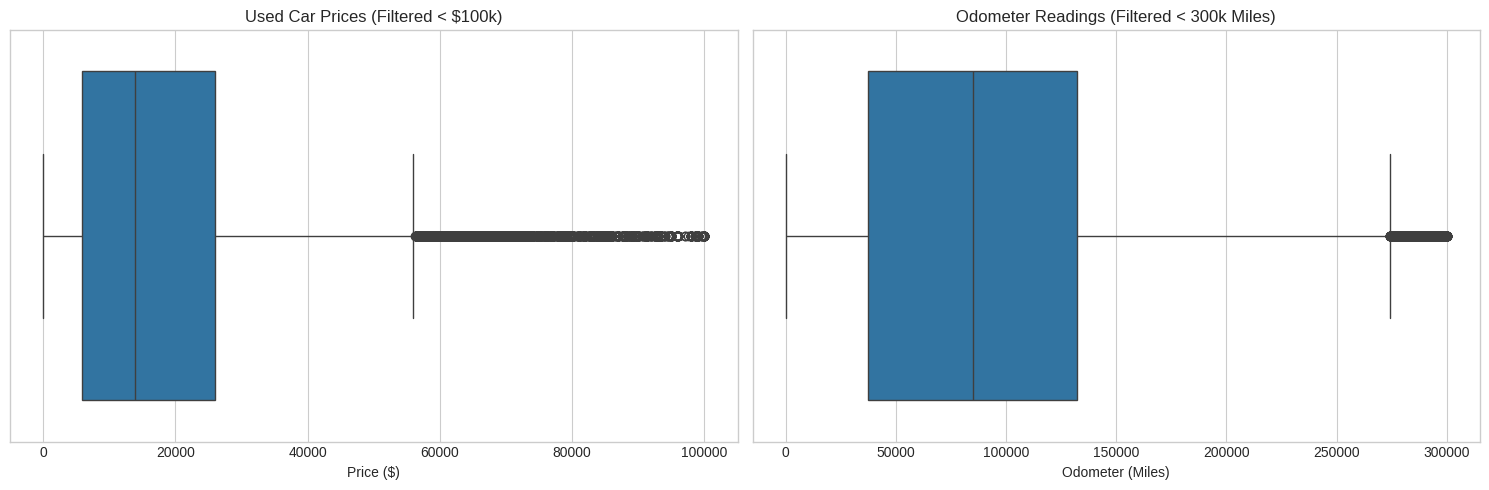

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

# Configure plotting style
plt.style.use('seaborn-v0_8-whitegrid')
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

# Plot Price Distribution (focusing on less than $100k to ignore extreme 3B+ outliers)
sns.boxplot(ax=axes[0], x=df[df['price'] < 100000]['price'])
axes[0].set_title('Used Car Prices (Filtered < $100k)')
axes[0].set_xlabel('Price ($)')

# Plot Odometer Distribution (focusing on less than 300k miles)
sns.boxplot(ax=axes[1], x=df[df['odometer'] < 300000]['odometer'])
axes[1].set_title('Odometer Readings (Filtered < 300k Miles)')
axes[1].set_xlabel('Odometer (Miles)')

plt.tight_layout()
plt.show()

### Data Preparation

After our initial exploration and fine-tuning of the business understanding, it is time to construct our final dataset prior to modeling.  Here, we want to make sure to handle any integrity issues and cleaning, the engineering of new features, any transformations that we believe should happen (scaling, logarithms, normalization, etc.), and general preparation for modeling with `sklearn`.

In [ ]:
# 1. Drop completely irrelevant identifier columns
df_cleaned = df.drop(columns=['id', 'VIN', 'region', 'state'])

# 2. Drop columns with excessive missing data (> 50% missing)
df_cleaned = df_cleaned.drop(columns=['size'])

# 3. Filter outliers in target 'price' and 'odometer'
# We remove cars priced under $500 (often placeholders) and over $100,000 (exotics/typos)
# We remove cars with fewer than 100 miles or more than 300,000 miles
df_cleaned = df_cleaned[
    (df_cleaned['price'] >= 500) &
    (df_cleaned['price'] <= 100000) &
    (df_cleaned['odometer'] >= 100) &
    (df_cleaned['odometer'] <= 300000) &
    (df_cleaned['year'].notna())
]

# 4. Simple Imputation for categorical missing values
# We will replace missing values in categorical columns with 'unknown'
cat_cols_to_fill = ['manufacturer', 'model', 'condition', 'cylinders', 'fuel', 'title_status', 'transmission', 'drive', 'type', 'paint_color']
for col in cat_cols_to_fill:
    if col in df_cleaned.columns:
        df_cleaned[col] = df_cleaned[col].fillna('unknown')

# Display cleaned dataframe info
print(f"Cleaned Dataset Shape: {df_cleaned.shape}")
display(df_cleaned.head())

Cleaned Dataset Shape: (373813, 13)


,price,year,manufacturer,model,condition,cylinders,fuel,odometer,title_status,transmission,drive,type,paint_color
27,33590,2014.0,gmc,sierra 1500 crew cab slt,good,8 cylinders,gas,57923.0,clean,other,unknown,pickup,white
28,22590,2010.0,chevrolet,silverado 1500,good,8 cylinders,gas,71229.0,clean,other,unknown,pickup,blue
29,39590,2020.0,chevrolet,silverado 1500 crew,good,8 cylinders,gas,19160.0,clean,other,unknown,pickup,red
30,30990,2017.0,toyota,tundra double cab sr,good,8 cylinders,gas,41124.0,clean,other,unknown,pickup,red
31,15000,2013.0,ford,f-150 xlt,excellent,6 cylinders,gas,128000.0,clean,automatic,rwd,truck,black


In [ ]:
from sklearn.model_selection import train_test_split

# Drop high-cardinality column 'model' for baseline modeling
df_model_ready = df_cleaned.drop(columns=['model'])

# Identify categorical columns to One-Hot Encode
cat_cols_to_encode = ['manufacturer', 'condition', 'cylinders', 'fuel', 'title_status', 'transmission', 'drive', 'type', 'paint_color']

# Convert categorical columns to numeric using get_dummies
df_encoded = pd.get_dummies(df_model_ready, columns=cat_cols_to_encode, drop_first=True)

# Separate features (X) and target (y)
X = df_encoded.drop(columns=['price'])
y = df_encoded['price']

# Train-Test Split (80% Train, 20% Test)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

print(f"Encoded Dataset Shape: {df_encoded.shape}")
print(f"Training set size: {X_train.shape[0]} samples")
print(f"Testing set size: {X_test.shape[0]} samples")

Encoded Dataset Shape: (373813, 101)
Training set size: 299050 samples
Testing set size: 74763 samples


### Modeling

With your (almost?) final dataset in hand, it is now time to build some models.  Here, you should build a number of different regression models with the price as the target.  In building your models, you should explore different parameters and be sure to cross-validate your findings.

In [ ]:
from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.metrics import mean_absolute_error, r2_score
import numpy as np

# Initialize Models
models = {
    'Linear Regression': LinearRegression(),
    'Ridge Regression (L2)': Ridge(alpha=1.0),
    'Lasso Regression (L1)': Lasso(alpha=1.0, max_iter=1000)
}

# Train and Evaluate each model
for name, model in models.items():
    model.fit(X_train, y_train)
    predictions = model.predict(X_test)

    mae = mean_absolute_error(y_test, predictions)
    r2 = r2_score(y_test, predictions)

    print(f"=== {name} ===")
    print(f"Test Mean Absolute Error (MAE): ${mae:,.2f}")
    print(f"Test R-squared (R2) Score:     {r2:.4f}\n")

=== Linear Regression ===
Test Mean Absolute Error (MAE): $6,107.48
Test R-squared (R2) Score:     0.6190

=== Ridge Regression (L2) ===
Test Mean Absolute Error (MAE): $6,107.58
Test R-squared (R2) Score:     0.6190

=== Lasso Regression (L1) ===
Test Mean Absolute Error (MAE): $6,108.42
Test R-squared (R2) Score:     0.6187



### Evaluation

With some modeling accomplished, we aim to reflect on what we identify as a high-quality model and what we are able to learn from this.  We should review our business objective and explore how well we can provide meaningful insight into drivers of used car prices.  Your goal now is to distill your findings and determine whether the earlier phases need revisitation and adjustment or if you have information of value to bring back to your client.

--- Top 10 Positive Drivers of Car Price (Ridge) ---


,Feature,Coefficient
12,manufacturer_ferrari,42604.813284
39,manufacturer_tesla,15267.307749
34,manufacturer_porsche,8840.816713
3,manufacturer_aston-martin,8040.227911
10,manufacturer_datsun,7009.851412
50,cylinders_12 cylinders,4691.071850
84,type_truck,3960.385479
82,type_pickup,3774.893068
81,type_other,3690.491725
36,manufacturer_rover,3554.965810



--- Top 10 Negative Drivers of Car Price (Ridge) ---


,Feature,Coefficient
58,fuel_electric,-18024.826236
59,fuel_gas,-14716.133491
60,fuel_hybrid,-14659.373540
62,fuel_unknown,-14549.431653
16,manufacturer_harley-davidson,-13278.448470
61,fuel_other,-11821.405458
51,cylinders_3 cylinders,-10481.798865
13,manufacturer_fiat,-10127.706947
30,manufacturer_mitsubishi,-8144.510252
65,title_status_parts only,-7572.029591


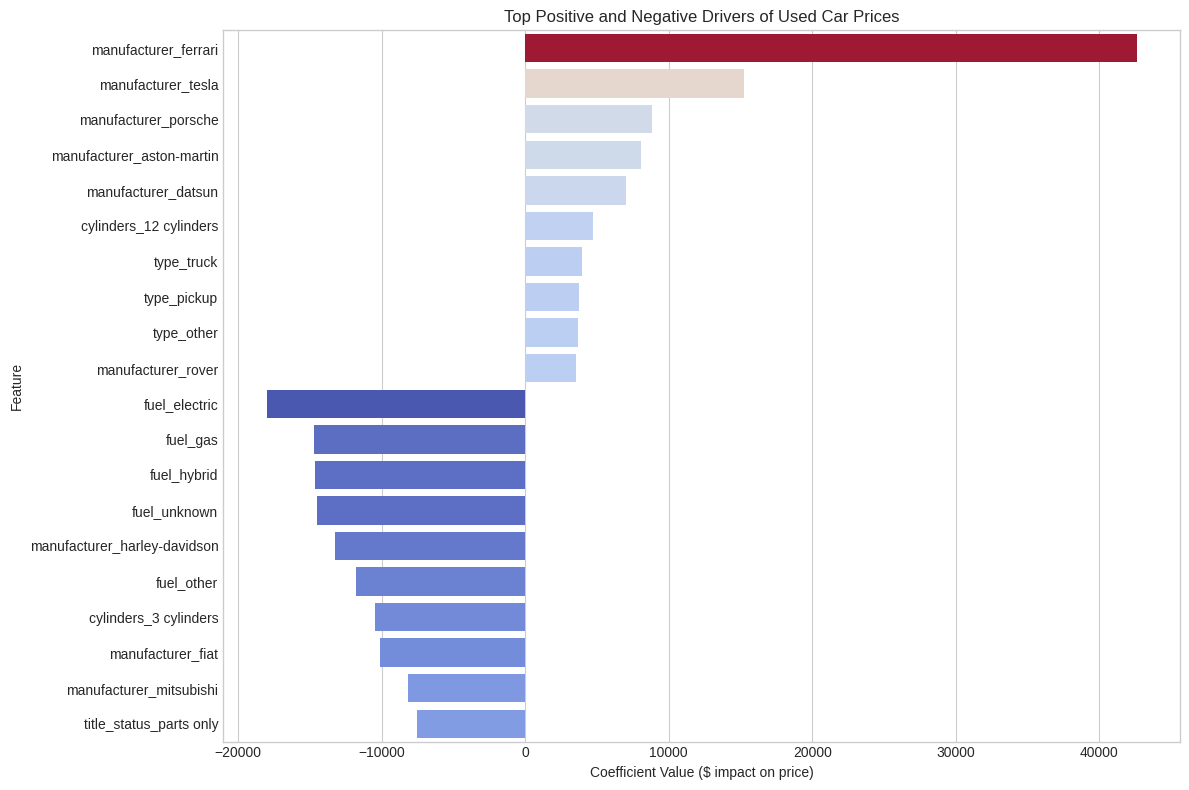

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Retrieve the Ridge model from our models dictionary
ridge_model = models['Ridge Regression (L2)']

# Map coefficients to feature names
coef_df = pd.DataFrame({
    'Feature': X.columns,
    'Coefficient': ridge_model.coef_
})

# Separate and sort by magnitude
top_positive = coef_df.sort_values(by='Coefficient', ascending=False).head(10)
top_negative = coef_df.sort_values(by='Coefficient', ascending=True).head(10)

print("--- Top 10 Positive Drivers of Car Price (Ridge) ---")
display(top_positive)

print("\n--- Top 10 Negative Drivers of Car Price (Ridge) ---")
display(top_negative)

# Plot top drivers together
drivers = pd.concat([top_positive, top_negative])
plt.figure(figsize=(12, 8))
sns.barplot(data=drivers, x='Coefficient', y='Feature', hue='Coefficient', palette='coolwarm', legend=False)
plt.title('Top Positive and Negative Drivers of Used Car Prices')
plt.xlabel('Coefficient Value ($ impact on price)')
plt.ylabel('Feature')
plt.tight_layout()
plt.show()

### Deployment

Now that we've settled on our models and findings, it is time to deliver the information to the client.  You should organize your work as a basic report that details your primary findings.  Keep in mind that your audience is a group of used car dealers interested in fine-tuning their inventory.